# Lab 04-02 · Charge, Coulomb's Law and Electric Fields

Companion to chapter [04-02](../../chapters/04-02-charge-coulomb-and-electric-fields.md). Handout: [README.md](README.md). The ngspice netlist [hbm.cir](hbm.cir) simulates Example 04-02.8; run it with `python tools/run_spice.py 04-02` from the repository root.

Each part computes fields by brute-force superposition and compares them with the chapter's closed forms. Cells marked **🔮 Predict** ask for a prediction *before* running.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp
from scipy.optimize import minimize_scalar
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
e, eps0, me = 1.602176634e-19, 8.8541878188e-12, 9.1093837139e-31
ke = 1 / (4 * math.pi * eps0)

def field(charges, point):
    # superposition: sum k q (r - r_i) / |r - r_i|^3 over point charges
    E = np.zeros(2)
    for q, pos in charges:
        d = np.asarray(point, float) - np.asarray(pos, float)
        E += ke * q * d / np.linalg.norm(d) ** 3
    return E

## Part 1 — Superposition by computer

Reproduce Example 04-02.3: +2 nC at (0, 0) and −2 nC at (4 cm, 0) acting on +1 nC at (2 cm, 3 cm).

**🔮 Predict:** the direction of the net force.

net force: (15.3397, 0.00e+00) uN, magnitude 15.3397 uN


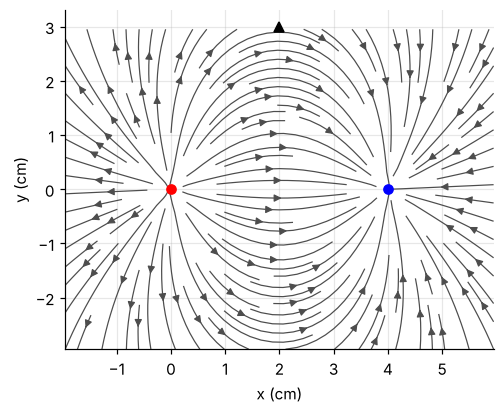

In [2]:
charges = [(2e-9, (0, 0)), (-2e-9, (0.04, 0))]
F = 1e-9 * field(charges, (0.02, 0.03))
print(f"net force: ({F[0]*1e6:.4f}, {F[1]*1e6:.2e}) uN, magnitude {np.linalg.norm(F)*1e6:.4f} uN")
x = np.linspace(-0.0195, 0.0595, 40); y = np.linspace(-0.0295, 0.0295, 30)   # grid avoids the charges
X, Y = np.meshgrid(x, y)
EX, EY = np.zeros_like(X), np.zeros_like(Y)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        EX[i, j], EY[i, j] = field(charges, (X[i, j], Y[i, j]))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.streamplot(X * 100, Y * 100, EX, EY, density=1.2, color="0.3", linewidth=0.8)
ax.plot([0], [0], "ro"); ax.plot([4], [0], "bo"); ax.plot([2], [3], "k^")
ax.set_xlabel("x (cm)"); ax.set_ylabel("y (cm)"); ax.set_aspect("equal"); plt.show()

The $y$-components cancel by symmetry and the force points along +$x$, from the positive charge toward the negative one, as the chapter predicted.

## Part 2 — Fields from integrals: the finite line

Chop Example 04-02.4's 2 mm line (10 nC/m) into $N$ point charges and sum their fields at 1 mm on the bisector.

**🔮 Predict:** how many segments for 0.1% accuracy?

In [3]:
lam, L, y0 = 10e-9, 2e-3, 1e-3
exact = lam / (2 * math.pi * eps0 * y0) * (L / 2) / math.sqrt(y0**2 + (L / 2)**2)
print(f"closed form: {exact:.1f} V/m")
for N in (2, 4, 10, 20, 100):
    xs = -L / 2 + (np.arange(N) + 0.5) * L / N          # midpoints of N segments
    Ey = sum(ke * lam * (L / N) * y0 / (xx**2 + y0**2) ** 1.5 for xx in xs)
    print(f"N = {N:4d}: {Ey:.1f} V/m, error {(Ey / exact - 1) * 100:+.4f}%")

closed form: 127103.2 V/m
N =    2: 128619.4 V/m, error +1.1929%
N =    4: 128079.4 V/m, error +0.7680%
N =   10: 127261.8 V/m, error +0.1248%
N =   20: 127142.9 V/m, error +0.0312%
N =  100: 127104.8 V/m, error +0.0012%


The midpoint sum converges quickly: between 10 and 20 segments reach 0.1% here (the error falls as $1/N^2$), because the observation point is as far away as the line is long. Closer to a line you need finer segments; this is how field solvers discretize conductors.

## Part 3 — The dipole's $1/r^3$

Compute the exact on-axis field of Example 04-02.6's dipole (±1 nC, 1 mm) from 2 mm to 1 m and fit the slope on log axes.

**🔮 Predict:** the slope far away, and how it changes close in.

far-field slope of log E against log r: -3.0000
exact / (2 k p / r^3) at r = 10 cm: 1.000050
exact / (2 k p / r^3) at r = 3 mm (three spacings): 1.0580


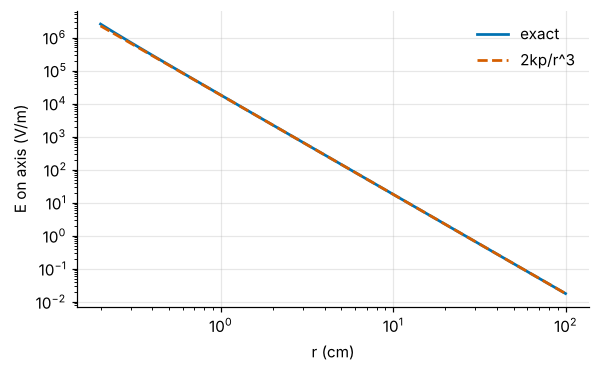

In [4]:
q, d = 1e-9, 1e-3
r = np.logspace(np.log10(2e-3), 0, 200)
E = ke * q * (1 / (r - d / 2) ** 2 - 1 / (r + d / 2) ** 2)
far = r > 0.05
slope = np.polyfit(np.log(r[far]), np.log(E[far]), 1)[0]
print(f"far-field slope of log E against log r: {slope:.4f}")
E10 = ke * q * (1 / (0.1 - d / 2) ** 2 - 1 / (0.1 + d / 2) ** 2)
print(f"exact / (2 k p / r^3) at r = 10 cm: {E10 / (2 * ke * q * d / 0.1**3):.6f}")
E3 = ke * q * (1 / (3e-3 - d / 2) ** 2 - 1 / (3e-3 + d / 2) ** 2)
print(f"exact / (2 k p / r^3) at r = 3 mm (three spacings): {E3 / (2 * ke * q * d / 3e-3**3):.4f}")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(r * 100, E, label="exact"); ax.loglog(r * 100, 2 * ke * q * d / r**3, "--", label="2kp/r^3")
ax.set_xlabel("r (cm)"); ax.set_ylabel("E on axis (V/m)"); ax.legend(); plt.show()

Far away the slope is −3: the two charges' $1/r^2$ fields cancel to leading order. Close in (within a few spacings) the approximation fails.

## Part 4 — Where is a ring's field largest?

Maximize $E_z(z)$ for a ring of radius 5 cm carrying 10 nC (Problem 04-02.6) numerically.

**🔮 Predict:** at what fraction of the radius?

In [5]:
Q, R = 1e-8, 0.05
Ez = lambda z: ke * Q * z / (z**2 + R**2) ** 1.5
res = minimize_scalar(lambda z: -Ez(z), bounds=(0, 0.2), method="bounded", options={"xatol": 1e-12})
print(f"maximum at z = {res.x*100:.4f} cm (R/sqrt2 = {R/math.sqrt(2)*100:.4f} cm), E = {Ez(res.x):.1f} V/m")
# the same field by integrating the ring numerically, piece by piece
Enum = quad(lambda phi: ke * (Q / (2 * math.pi)) * res.x / (res.x**2 + R**2) ** 1.5, 0, 2 * math.pi)[0]
print(f"by integrating around the ring: {Enum:.1f} V/m")

maximum at z = 3.5355 cm (R/sqrt2 = 3.5355 cm), E = 13837.2 V/m
by integrating around the ring: 13837.2 V/m


## Part 5 — An electron between deflection plates

Problem 04-02.11's electrons (2 kV acceleration, plates 2 cm long, 5 mm apart, 50 V) are integrated numerically and compared with the parabola.

**🔮 Predict:** the deflection at the exit, in mm.

In [6]:
Va, Vd, Lp, gap = 2000.0, 50.0, 0.02, 0.005
v0 = math.sqrt(2 * e * Va / me)
a = e * (Vd / gap) / me
sol = solve_ivp(lambda t, s: [s[2], s[3], 0.0, a], (0, Lp / v0), [0, 0, v0, 0], rtol=1e-12, atol=1e-15)
print(f"entry speed {v0:.4e} m/s; exit deflection {sol.y[1, -1]*1e3:.4f} mm (parabola {0.5*a*(Lp/v0)**2*1e3:.4f} mm)")
print(f"exit angle tan = {sol.y[3, -1]/v0:.5f}  (Vd L / (2 Va d) = {Vd*Lp/(2*Va*gap):.5f})")

entry speed 2.6524e+07 m/s; exit deflection 0.5000 mm (parabola 0.5000 mm)
exit angle tan = 0.05000  (Vd L / (2 Va d) = 0.05000)


## Part 6 — ESD pulses: HBM against the IEC gun

The idealized currents of the human-body model (100 pF, 1.5 kΩ) and the IEC 61000-4-2 system-level network (150 pF, 330 Ω) at the same 8 kV.

**🔮 Predict:** the ratio of peak currents and of delivered charges.

HBM: peak 5.333 A, tau 150.0 ns, charge 0.8000 uC (CV = 0.80 uC)
IEC: peak 24.242 A, tau 49.5 ns, charge 1.2000 uC (CV = 1.20 uC)


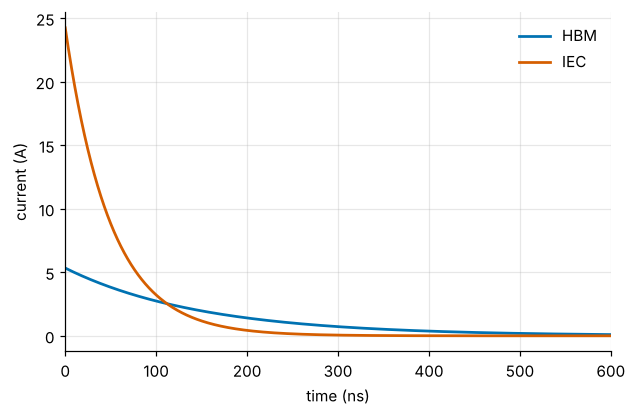

In [7]:
t = np.linspace(0, 3e-6, 30001)                  # long enough for the HBM tail
for name, Cc, Rr in (("HBM", 100e-12, 1500.0), ("IEC", 150e-12, 330.0)):
    i = 8000 / Rr * np.exp(-t / (Rr * Cc))
    print(f"{name}: peak {8000/Rr:.3f} A, tau {Rr*Cc*1e9:.1f} ns, charge {np.trapezoid(i, t)*1e6:.4f} uC (CV = {Cc*8000*1e6:.2f} uC)")
    plt.plot(t * 1e9, i, label=name)
plt.xlim(0, 600); plt.xlabel("time (ns)"); plt.ylabel("current (A)"); plt.legend(); plt.show()

The system-level pulse peaks 4.5 times higher and delivers 50% more charge in a third of the time, which is why connectors need protection beyond what a chip's HBM rating covers.

## Your turn

1. In Part 2, move the observation point to 0.1 mm from the line. How many segments do you now need for 0.1%? Why?
2. In Part 3, compute the field on the perpendicular bisector instead, and check the slope and the ratio to $k_ep/r^3$.